In [38]:
import sys, os, datetime, importlib

import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
import tqdm

In [2]:
import util_collector
importlib.reload(util_collector)

<module 'util_collector' from '/mnt/c/Users/user/Desktop/rnd/AISat/VolumeInversion/util_collector.py'>

In [31]:
import script_CoreExplorer; importlib.reload(script_CoreExplorer)
#train = (read[:50,0,None,:16,:16].flatten(2).to(torch.float32)/255).to('cuda')
train = script_CoreExplorer.get_randoms(1, reshape=True)
train = [train['S'].real, train['T'].real, train['rho'].real, train['rf'].real, train['rf'].imag]
data_shapes = [el.shape[1:] for el in train]
vl = [torch.as_tensor(el).prod() for el in data_shapes]
vlen = sum(vl)

collector = util_collector.Dataset('em_randoms.hdf5')
def gen_feed(count=100, collector=None):
    train = script_CoreExplorer.get_randoms(count, reshape=False, collector=collector)
    train = [train['S'].real, train['T'].real, train['rho'].real, train['rf'].real, train['rf'].imag]
    feed = torch.cat([torch.as_tensor(el).flatten(1) for el in train], dim=1)[:,None,:].to('cuda', torch.float32)
    return feed
feed = gen_feed(5000, collector)
collector.close()
#np.concatenate(list(train.values()), axis=1).shape

100%|████████████████████████████████████████████████████████████████████████████| 10000/10000 [01:35<00:00, 105.15it/s]


-394.3914794921875


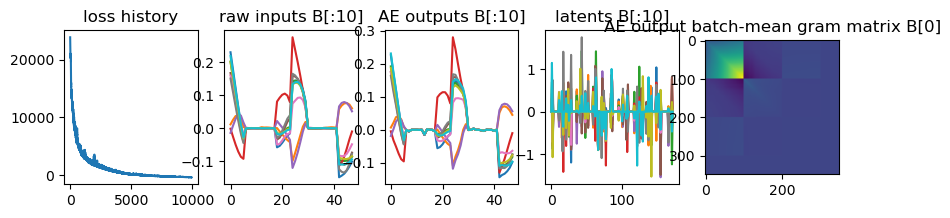

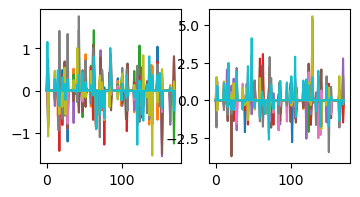

In [326]:
import nn_util; importlib.reload(nn_util)
import nn_enc; importlib.reload(nn_enc)

# weighted loss for different data types
loss_wgt = torch.ones(vlen)
loss_wgt[:vl[0]+vl[1]+vl[2]] = 1
loss_wgt[-(vl[3]+vl[4]):] = 10000
loss_wgt = loss_wgt[None,None,:].to('cuda', torch.float32)
def calc_loss(x, y):
    #loss_dot = -(y * x * loss_wgt).sum(dim=-1).mean()
    loss_mse = ((y - x).pow(2) * loss_wgt).sum(dim=-1).mean()
    return loss_mse - F.cosine_similarity(x, y, dim=-1).sum(dim=-1).mean()

#model_ae = nn_enc.VAE_MLP_Tied(vlen, 372, 172).to('cuda', torch.float32)
model_ae = nn_enc.VAE_MLP(vlen, 128, 172, 2, 'silu').to('cuda', torch.float32)
ae_wrapper = nn_enc.VAE_SparseWrapper(model_ae, r=8)

d_train = feed[:-feed.shape[0]//5] # 80/20 ratio
d_valid = feed[-feed.shape[0]//5:]

steps = 10000
loss_hist = []
opt = torch.optim.AdamW(model_ae.parameters(), lr=0.100, weight_decay=1e-3, fused=True)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=20, factor=0.99)
for i in tqdm.tqdm(range(steps)):
    opt.zero_grad()
    loss = model_ae.get_loss(d_train[:,0], d_train[:,0], calc_loss)
    if i % 10 == 0 : loss = loss + 0.1 * ae_wrapper.get_loss(d_train[:,0], d_train[:,0], calc_loss)
    loss.backward()
    v_loss = loss = model_ae.get_loss(d_valid[:,0], d_valid[:,0], calc_loss)
    torch.nn.utils.clip_grad_norm_(model_ae.parameters(), 0.01)
    opt.step()
    sched.step(v_loss.detach())
    loss_hist.append(loss.detach().item())
print(loss.detach().item())
y = model_ae(d_valid)
plt.figure(figsize=(10,2))
plt.subplot(1,5,1); plt.plot(loss_hist[50:]); plt.title('loss history')
plt.subplot(1,5,2); plt.plot(feed.cpu()[:10,0,300:].T); plt.title('raw inputs B[:10]')
plt.subplot(1,5,3); plt.plot(model_ae(feed).detach().cpu()[:10,0,300:].T); plt.title('AE outputs B[:10]')
plt.subplot(1,5,4); plt.plot(model_ae.enc(feed)[:10,0].T.cpu().detach()); plt.title('latents B[:10]')
plt.subplot(1,5,5); plt.imshow((y * y.transpose(-1,-2)).mean(dim=0).cpu().detach()); plt.title('AE output batch-mean gram matrix B[0]')
plt.show()

feed0 = model_ae.enc(feed).detach()   # input embedding
feed1 = model_ae.enc(F.dropout(feed, p=0.8)).detach() # randomly masked input to embedding
plt.figure(figsize=(4,2))
plt.subplot(1,2,1); plt.plot(feed0.detach().cpu()[:10,0,:].T);
plt.subplot(1,2,2); plt.plot(feed1.detach().cpu()[:10,0,:].T);
plt.show()